<a href="https://colab.research.google.com/github/SusmoyDas98/CSE463-Project/blob/main/cse463_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Mirror-Invariant Handwritten Digit Recognition Model**

In [60]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [68]:
# loading the mnist dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

In [69]:
# Normalizing the pixel values

x_train = x_train.astype('float32')/255.0
x_test = x_test.astype('float32')/255.0


x_train = np.expand_dims(x_train, axis = -1)
x_test = np.expand_dims(x_test, axis = -1)

In [70]:
# One hot encoding
y_train = to_categorical(y_train,num_classes=10)
y_test =  to_categorical(y_test,  num_classes = 10)

In [71]:
# Training and validation split

x_train, x_val, y_train, y_val = train_test_split(
    x_train, y_train,  test_size = 0.1, random_state=42
)

In [72]:
# The CNN Model
def create_cnn_model():
    inputs = Input(shape = (28,28,1))
    x = Conv2D(32, (3,3), activation = 'relu',  padding = 'same')(inputs)
    x = Conv2D(64, (3,3), activation = 'relu', padding = 'same')(x)
    x = MaxPooling2D(pool_size=(2,2))(x)
    x = Flatten()(x)
    features = Dense(128, activation = 'relu')(x)
    outputs = Dense(10, activation = 'softmax')(features)
    model = Model(inputs = inputs,   outputs = [outputs, features])
    return model
model = create_cnn_model()

In [73]:
optimizer = Adam(learning_rate = 0.001)
loss_fn_classification = tf.keras.losses.CategoricalCrossentropy()
loss_fn_consistency = tf.keras.losses.MeanSquaredError()
lambda_consistency = 0.5

In [74]:
# training
batch_size = 64
epochs = 10
train_dataset = tf.data.Dataset.from_tensor_slices((x_train,y_train))
train_dataset = train_dataset.shuffle(buffer_size = 1024).batch(batch_size)

for epoch in range(epochs):
    print(f"Epoch {epoch+1}/{epochs}")
    total_loss = 0
    for step, (images, labels) in enumerate(train_dataset):
        with tf.GradientTape() as tape:
            # Forward passing Original image
            logits, features_orig = model(images, training = True)

            # Generating Mirrored Version
            mirrored_images = tf.image.flip_left_right(images)
            logits_mirror, features_mirror = model(mirrored_images, training = True)

            # Classification loss for original images

            loss_cls = loss_fn_classification(labels, logits)

            # Loss for mirrored images

            loss_consistency =  loss_fn_consistency(features_orig, features_mirror)

            # Total Loss

            loss = loss_cls + lambda_consistency * loss_consistency

        # Backpropogation
        grads = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(grads, model.trainable_variables))

        total_loss += loss.numpy()

    print(f"Total loss for epoch {epoch+1}: {total_loss:4f}")




Epoch 1/10
Total loss for epoch 1: 157.535095
Epoch 2/10
Total loss for epoch 2: 59.642799
Epoch 3/10
Total loss for epoch 3: 38.891720
Epoch 4/10
Total loss for epoch 4: 26.510431
Epoch 5/10
Total loss for epoch 5: 18.681808
Epoch 6/10
Total loss for epoch 6: 13.828063
Epoch 7/10
Total loss for epoch 7: 11.010233
Epoch 8/10
Total loss for epoch 8: 9.014235
Epoch 9/10
Total loss for epoch 9: 8.276753
Epoch 10/10
Total loss for epoch 10: 7.585230


In [75]:
# evaluation
def evaluate(model, x, y):
    logits, feature_outputs = model(x, training = False)
    preds = np.argmax(logits.numpy(), axis = 1)
    labels = np.argmax(y, axis = 1)
    acc = np.mean(preds == labels)
    return acc

In [76]:
# original image testing
acc_orig =  evaluate(model, x_test, y_test)
print("Accuracy on Actual MNIST Image", acc_orig)

Accuracy on Actual MNIST Image 0.9894


In [77]:
# mirror image testing
x_test_mirror = tf.image.flip_left_right(x_test)
acc_mirror = evaluate(model, x_test_mirror, y_test)
print("Accuracy on mirrored Image", acc_mirror)

Accuracy on mirrored Image 0.9651


###**Confusion Matrix for Mirror-Invariant Model**

In [78]:
from sklearn.metrics import confusion_matrix

####**For Original Images**

<Figure size 800x800 with 0 Axes>

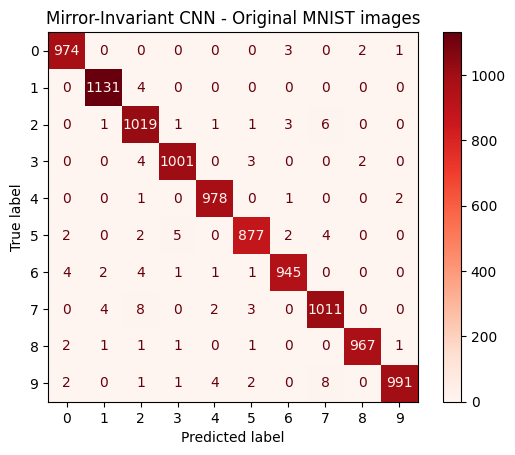

In [79]:

# Predictions for original images

invariant_model_class_outputs_original, invariant_model_feature_outputs_original = (
    model(x_test, training = False)
)

# Exact true labels from one-hot encoded test labels
true_test_class_labels = np.argmax(y_test, axis = 1)

# Predicted lables for original images
predicted_class_labels_invariant_original = np.argmax(
    invariant_model_class_outputs_original.numpy(), axis = 1
)

# Computing confusion matrix
confusion_matrix_invariant_original = confusion_matrix(
    true_test_class_labels,
    predicted_class_labels_invariant_original
)

confusion_display_invariant_original = ConfusionMatrixDisplay(
    confusion_matrix = confusion_matrix_invariant_original,
    display_labels = range(10)
)

plt.figure(figsize=(8,8))
confusion_display_invariant_original.plot(cmap = 'Reds', values_format = 'd')
plt.title(f"Mirror-Invariant CNN - Original MNIST images")
plt.show()

####**For Mirrored Images**

<Figure size 800x800 with 0 Axes>

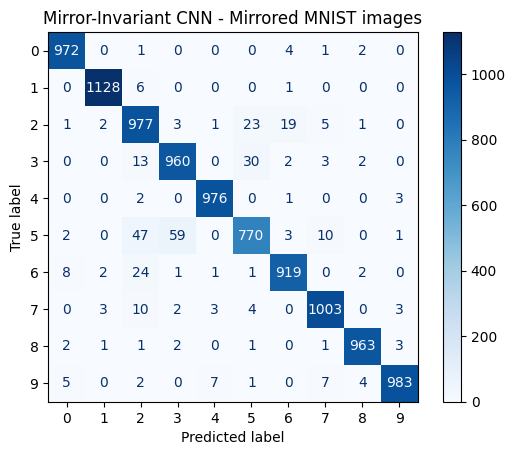

In [80]:

# Predictions for mirrored images

mirrored_test_images_for_invariant_model = tf.image.flip_left_right(x_test)

invariant_model_class_outputs_mirrored, invariant_model_feature_outputs_mirrored = (
    model(mirrored_test_images_for_invariant_model, training = False)
)

# Predicted lables for mirrored images
predicted_class_labels_invariant_mirrored = np.argmax(
    invariant_model_class_outputs_mirrored.numpy(), axis = 1
)

# Computing confusion matrix
confusion_matrix_invariant_mirrored = confusion_matrix(
    true_test_class_labels,
    predicted_class_labels_invariant_mirrored
)

confusion_display_invariant_mirrored = ConfusionMatrixDisplay(
    confusion_matrix = confusion_matrix_invariant_mirrored,
    display_labels = range(10)
)

plt.figure(figsize=(8,8))
confusion_display_invariant_mirrored.plot(cmap = 'Blues', values_format = 'd')
plt.title(f"Mirror-Invariant CNN - Mirrored MNIST images")
plt.show()

##**Classification Report**

In [81]:
from sklearn.metrics import classification_report

# Predictions for original MNIST images

predicted_labels_invariant_original = np.argmax(invariant_model_class_outputs_original.numpy(), axis = 1)
true_labels_invariant = np.argmax(y_test, axis = 1)
report_invariant_org = classification_report(true_labels_invariant,predicted_labels_invariant_original )
print(f"Classification Report - Mirror Invariant CNN on Original Images:\n{report_invariant_org}")


Classification Report - Mirror Invariant CNN on Original Images:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.98      0.99      0.98      1032
           3       0.99      0.99      0.99      1010
           4       0.99      1.00      0.99       982
           5       0.99      0.98      0.99       892
           6       0.99      0.99      0.99       958
           7       0.98      0.98      0.98      1028
           8       1.00      0.99      0.99       974
           9       1.00      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [82]:
# Predictions on Mirrored Images
predicted_labels_invariant_mirrored = np.argmax(invariant_model_class_outputs_mirrored.numpy(), axis=1)
report_invariant_mirr  = classification_report(true_labels_invariant, predicted_labels_invariant_mirrored)
print(f"Classification Report - Mirror Invariant CNN on Mirrored Images:\n{report_invariant_mirr}")

Classification Report - Mirror Invariant CNN on Mirrored Images:
              precision    recall  f1-score   support

           0       0.98      0.99      0.99       980
           1       0.99      0.99      0.99      1135
           2       0.90      0.95      0.92      1032
           3       0.93      0.95      0.94      1010
           4       0.99      0.99      0.99       982
           5       0.93      0.86      0.89       892
           6       0.97      0.96      0.96       958
           7       0.97      0.98      0.97      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.97      0.98      1009

    accuracy                           0.97     10000
   macro avg       0.96      0.96      0.96     10000
weighted avg       0.97      0.97      0.96     10000



#**Baseline Handwritten Digit Recognition**

In [83]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Input, Conv2D,  MaxPooling2D, Flatten, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split

In [84]:
(X_train, y_train), (X_test, y_test)= keras.datasets.mnist.load_data()

In [85]:
# Normalizing the data
X_train = X_train.astype('float32')/255.0
X_test =  X_test.astype('float32')/255.0

In [86]:
X_train = np.expand_dims(X_train, -1)
X_test = np.expand_dims(X_test, -1)

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

In [87]:
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size = 0.1, random_state = 42)

In [88]:
def create_baseline_cnn():
    inputs = Input(shape = (28,28,1))
    x = Conv2D(32, (3,3), activation = 'relu', padding = 'same')(inputs)
    x = Conv2D(64, (3,3), activation = 'relu', padding = 'same')(x)
    x = MaxPooling2D((2,2))(x)
    x = Flatten()(x)
    x = Dense(128, activation = 'relu')(x)
    outputs = Dense(10, activation = 'softmax')(x)
    return Model(inputs, outputs)


In [89]:
Usual_baseline_model = create_baseline_cnn()
Usual_baseline_model.compile(
    optimizer = Adam(0.001),
    loss = 'categorical_crossentropy',
    metrics = ['accuracy']
)

In [90]:
history = Usual_baseline_model.fit(
    X_train, y_train, validation_data = (X_val, y_val), epochs = 10,
    batch_size = 128,
    verbose = 1
)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.8892 - loss: 0.3698 - val_accuracy: 0.9802 - val_loss: 0.0712
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9864 - loss: 0.0460 - val_accuracy: 0.9882 - val_loss: 0.0390
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9902 - loss: 0.0295 - val_accuracy: 0.9887 - val_loss: 0.0366
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9932 - loss: 0.0194 - val_accuracy: 0.9903 - val_loss: 0.0362
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9958 - loss: 0.0128 - val_accuracy: 0.9877 - val_loss: 0.0421
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9971 - loss: 0.0090 - val_accuracy: 0.9913 - val_loss: 0.0360
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.9976 - loss: 0.0077 - val_accuracy: 0.9887 - val_loss: 0.0457
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9978 - loss: 0.0071 - val_accuracy: 0

In [91]:
# Evaluation
x_test_mirror = tf.image.flip_left_right(X_test)
baseline_accuracy_origial = Usual_baseline_model.evaluate(X_test, y_test, verbose = 0)[1]
baseline_accuracy_mirror = Usual_baseline_model.evaluate(x_test_mirror, y_test, verbose = 0)[1]

In [92]:
print(f"Baseline CNN accuracy for original dataset images: {baseline_accuracy_origial}")
print(f"Baseline CNN accuracy for Mirrored version of dataset images: {baseline_accuracy_mirror}")

Baseline CNN accuracy for original dataset images: 0.9886000156402588
Baseline CNN accuracy for Mirrored version of dataset images: 0.3813999891281128


###**Confusion Matrix for Baseline Model**

In [93]:
from sklearn.metrics import confusion_matrix

####**For Original Images**

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


<Figure size 800x800 with 0 Axes>

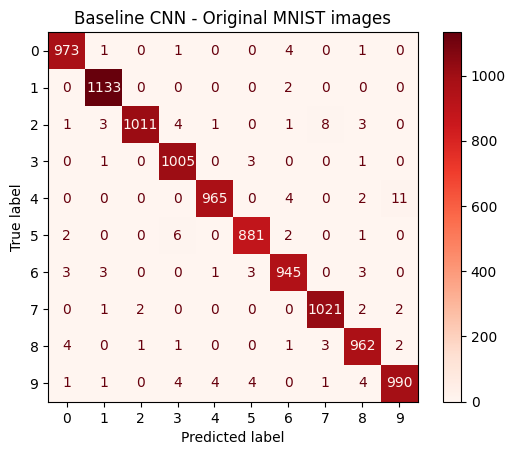

In [94]:

# Predictions for original images

baseline_model_class_outputs_original = Usual_baseline_model.predict(X_test)

# Exact true labels from one-hot encoded test labels
true_test_class_labels_baseline_model = np.argmax(y_test, axis = 1)

# Predicted lables for original images
predicted_class_labels_baseline_original = np.argmax(
    baseline_model_class_outputs_original, axis = 1
)

# Computing confusion matrix
confusion_matrix_baseline_original = confusion_matrix(
    true_test_class_labels_baseline_model,
    predicted_class_labels_baseline_original
)

confusion_display_baseline_original = ConfusionMatrixDisplay(
    confusion_matrix = confusion_matrix_baseline_original,
    display_labels = range(10)
)

plt.figure(figsize=(8,8))
confusion_display_baseline_original.plot(cmap = 'Reds', values_format = 'd')
plt.title(f"Baseline CNN - Original MNIST images")
plt.show()

####**For Mirrored Images**

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


<Figure size 800x800 with 0 Axes>

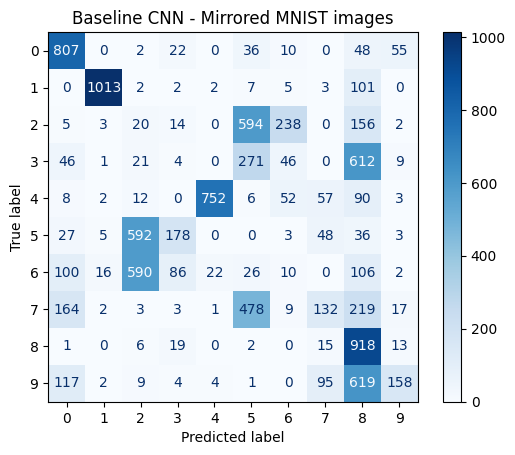

In [95]:

# Predictions for mirrored images

mirrored_test_images_for_baseline_model = tf.image.flip_left_right(x_test)

# Classification outputs
baseline_model_class_outputs_mirrored = Usual_baseline_model.predict(
    mirrored_test_images_for_baseline_model
)

# Predicted lables for mirrored images
predicted_class_labels_baseline_mirrored = np.argmax(
    baseline_model_class_outputs_mirrored, axis = 1
)

# Computing confusion matrix
confusion_matrix_baseline_mirrored = confusion_matrix(
    true_test_class_labels_baseline_model,
    predicted_class_labels_baseline_mirrored
)

confusion_display_baseline_mirrored = ConfusionMatrixDisplay(
    confusion_matrix = confusion_matrix_baseline_mirrored,
    display_labels = range(10)
)

plt.figure(figsize=(8,8))
confusion_display_baseline_mirrored.plot(cmap = 'Blues', values_format = 'd')
plt.title(f"Baseline CNN - Mirrored MNIST images")
plt.show()

##**Classification Report**

In [104]:
from sklearn.metrics import classification_report

# Predictions for original MNIST images

predicted_labels_baseline_original = np.argmax(baseline_model_class_outputs_original, axis = 1)
true_labels_baseline = np.argmax(y_test, axis = 1)
report_baseline_org = classification_report(true_labels_baseline,predicted_labels_baseline_original )
print(f"Classification Report - Baseline CNN on Original Images:\n{report_baseline_org}")


Classification Report - Baseline CNN on Original Images:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.99      1.00      0.99      1135
           2       1.00      0.98      0.99      1032
           3       0.98      1.00      0.99      1010
           4       0.99      0.98      0.99       982
           5       0.99      0.99      0.99       892
           6       0.99      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.98      0.99      0.99       974
           9       0.99      0.98      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



In [105]:
# Predictions on Mirrored Images
predicted_labels_baseline_mirrored = np.argmax(baseline_model_class_outputs_mirrored, axis=1)
report_baseline_mirr  = classification_report(true_labels_baseline, predicted_labels_baseline_mirrored)
print(f"Classification Report - Baseline CNN on Mirrored Images:\n{report_baseline_mirr}")

Classification Report - Baseline CNN on Mirrored Images:
              precision    recall  f1-score   support

           0       0.63      0.82      0.72       980
           1       0.97      0.89      0.93      1135
           2       0.02      0.02      0.02      1032
           3       0.01      0.00      0.01      1010
           4       0.96      0.77      0.85       982
           5       0.00      0.00      0.00       892
           6       0.03      0.01      0.02       958
           7       0.38      0.13      0.19      1028
           8       0.32      0.94      0.47       974
           9       0.60      0.16      0.25      1009

    accuracy                           0.38     10000
   macro avg       0.39      0.37      0.35     10000
weighted avg       0.40      0.38      0.35     10000



##**Model Summary**

###**Baseline**

In [100]:
Usual_baseline_model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_5 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,877,600 (18.61 MB)

 Trainable params: 1,625,866 (6.20 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,251,734 (12.40 MB)

##**Mirror-Invariant Handwritten Digit Recognition Model**

In [101]:
model.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 128)            │     1,605,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,625,866 (6.20 MB)

 Trainable params: 1,625,866 (6.20 MB)

 Non-trainable params: 0 (0.00 B)

# **Original vs Mirrored Accuracy**

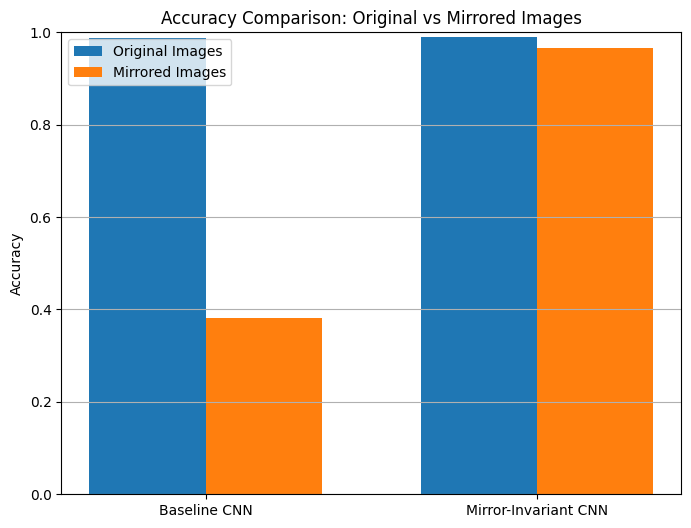

In [102]:
models= ['Baseline CNN', 'Mirror-Invariant CNN']
original= [baseline_accuracy_origial, acc_orig]
mirrored= [baseline_accuracy_mirror, acc_mirror]

x= np.arange(len(models))
width= 0.35

plt.figure(figsize=(8,6))
plt.bar(x - width/2, original, width, label='Original Images')
plt.bar(x + width/2, mirrored, width, label='Mirrored Images')

plt.ylabel('Accuracy')
plt.title('Accuracy Comparison: Original vs Mirrored Images')
plt.xticks(x, models)
plt.ylim(0, 1)
plt.legend()
plt.grid(axis='y')
plt.show()

# **Prediction Confidence Histogram: Original vs Mirrored**

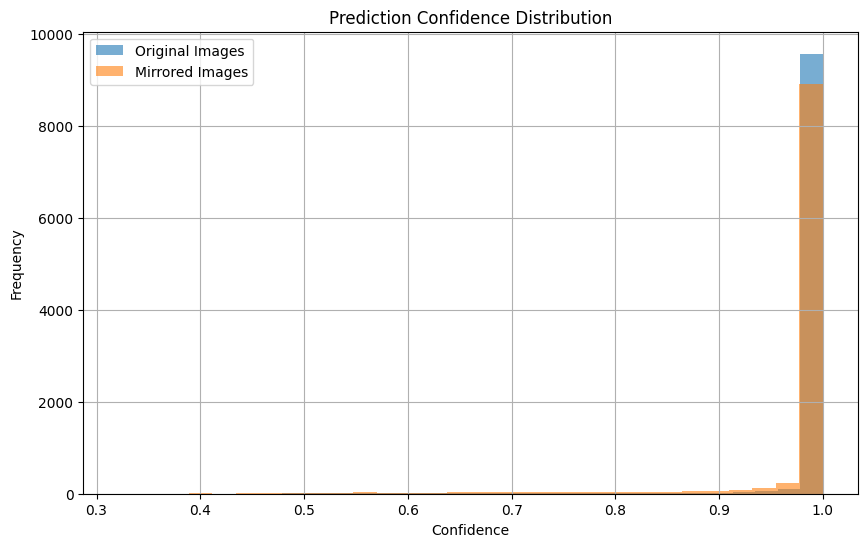

In [103]:
logits_orig, _ = model(x_test, training=False)
logits_mirror, _ =model(x_test_mirror, training=False)

conf_orig = np.max(logits_orig.numpy(), axis=1)
conf_mirror = np.max(logits_mirror.numpy(), axis=1)

plt.figure(figsize=(10, 6))
plt.hist(conf_orig, bins=30, alpha=0.6, label='Original Images')
plt.hist(conf_mirror, bins=30, alpha=0.6, label='Mirrored Images')

plt.title('Prediction Confidence Distribution')
plt.xlabel('Confidence')
plt.ylabel('Frequency')
plt.legend()
plt.grid(True)
plt.show()